### Data Investigation

Data obtained by using the following website:

- WAVE: https://data.marine.copernicus.eu/product/GLOBAL_ANALYSISFORECAST_WAV_001_027/download?dataset=cmems_mod_glo_wav_anfc_0.083deg_PT3H-i_202411

- WIND: https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=download

In [ ]:
import xarray as xr

# Load the dataset
df_wave = xr.open_dataset("data/cmems_mod_glo_wav_anfc_0.083deg_PT3H-i_1793025395853.nc")

In [30]:
# Check the data variables in the dataset
print("Available data variables:", list(df_wave.data_vars.keys()))

# Get the attributes of the variables
print("Attributes of VHM0:", df_wave["VHM0"].attrs)
print("Attributes of VTM01_WW:", df_wave["VTM01_WW"].attrs)

Available data variables: ['VHM0', 'VTM01_WW']
Attributes of VHM0: {'units': 'm', 'standard_name': 'sea_surface_wave_significant_height', 'long_name': 'Spectral significant wave height (Hm0)', 'WMO_code': np.int32(100), 'cell_methods': 'time:point area:mean', 'type_of_analysis': 'spectral analysis'}
Attributes of VTM01_WW: {'units': 's', 'standard_name': 'sea_surface_wind_wave_mean_period', 'long_name': 'Spectral moments (0,1) wind wave period', 'WMO_code': np.int32(223), 'cell_methods': 'time:point area:mean', 'type_of_analysis': 'spectral analysis'}


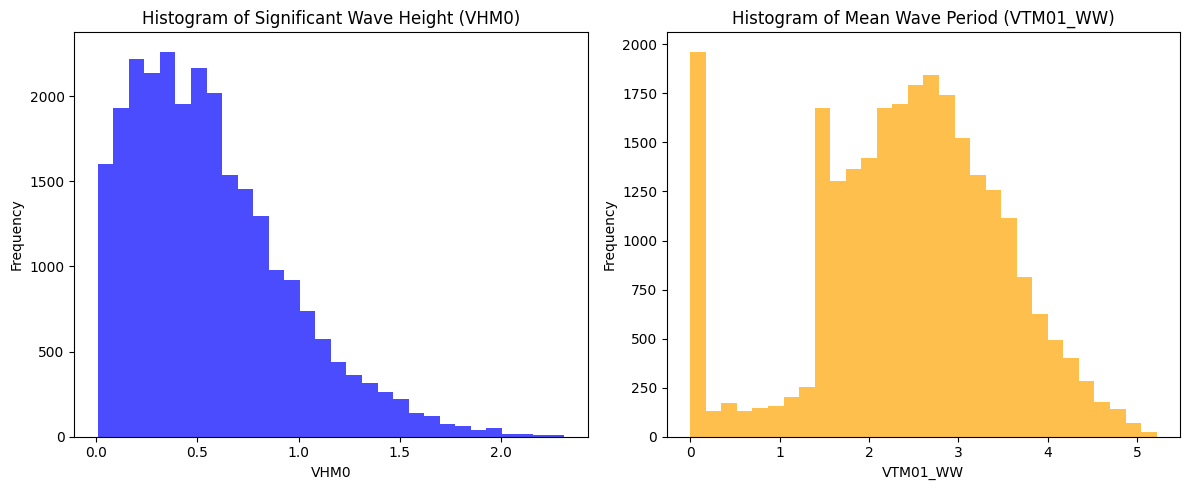

In [33]:
import numpy as np
import matplotlib.pyplot as plt

vhm0 = df_wave["VHM0"].values.ravel()                   # Raylegh distribution
vtm01 = df_wave["VTM01_WW"].values.ravel()           # Weibull/Normal/Gaussian distribution

# Remove NaN and infinite values
vhm0 = vhm0[np.isfinite(vhm0)]
vtm01 = vtm01[np.isfinite(vtm01)]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].hist(vhm0, bins=30, color="blue", alpha=0.7)
ax[0].set_title("Histogram of Significant Wave Height (VHM0)")
ax[0].set_xlabel("VHM0")
ax[0].set_ylabel("Frequency")

ax[1].hist(vtm01, bins=30, color="orange", alpha=0.7)
ax[1].set_title("Histogram of Mean Wave Period (VTM01_WW)")
ax[1].set_xlabel("VTM01_WW")
ax[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [39]:
import pandas as pd

# Select the nearest grid point to your location
point = df_wave.sel(latitude=40, longitude=-30, method="nearest")

# Create a three-column table
df_table = point[["VHM0", "VTM01_WW"]].to_dataframe().reset_index()

# Keep and rename the requested columns
df_table = df_table[["time", "VHM0", "VTM01_WW"]].rename(
    columns={
        "VHM0": "vhm0",
        "VTM01_WW": "vtm01",
    }
)

df_table.head(50)

,time,vhm0,vtm01
0,2025-01-05 00:00:00,0.65,2.79
1,2025-01-05 03:00:00,0.47,2.42
2,2025-01-05 06:00:00,0.33,1.89
3,2025-01-05 09:00:00,0.56,2.64
4,2025-01-05 12:00:00,0.59,2.73
5,2025-01-05 15:00:00,0.80,3.12
6,2025-01-05 18:00:00,1.09,3.58
7,2025-01-05 21:00:00,1.62,4.25
8,2025-01-06 00:00:00,1.95,4.63
9,2025-01-06 03:00:00,1.81,4.83


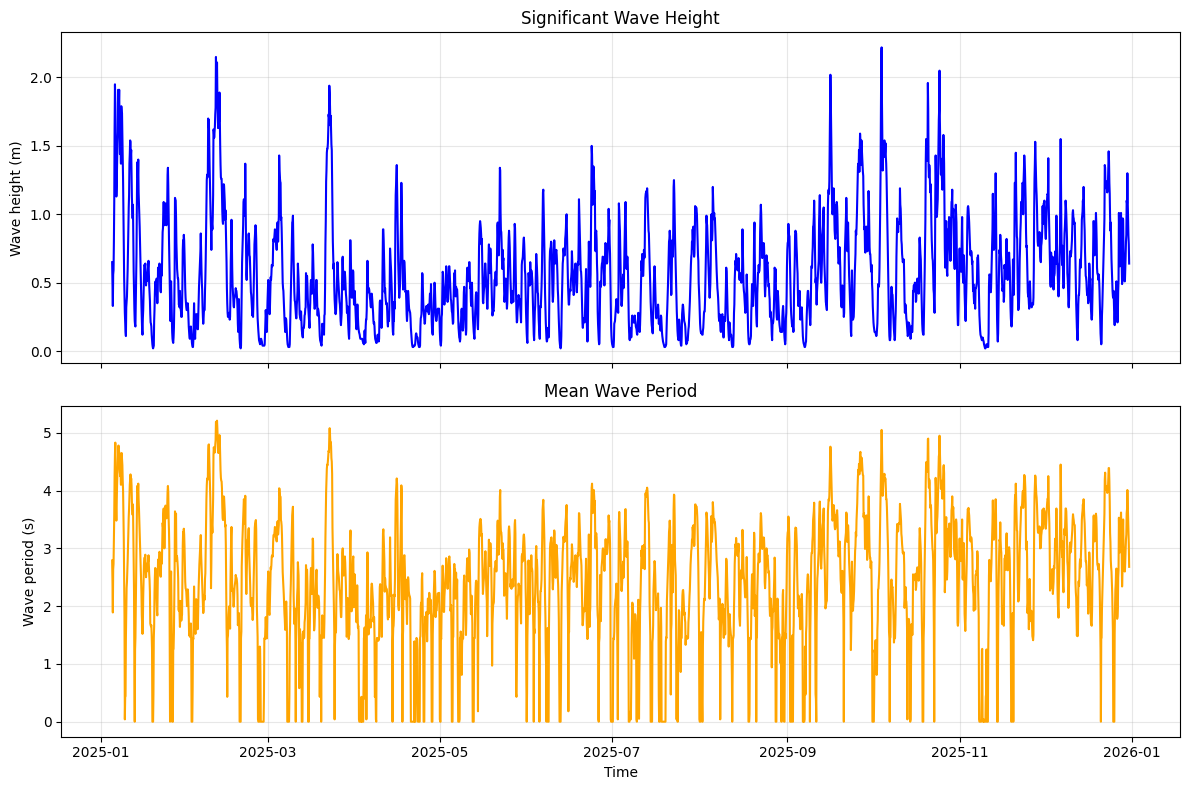

In [45]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

ax1.plot(
    df_table["time"],
    df_table["vhm0"],
    color="blue",
)
ax1.set_ylabel("Wave height (m)")
ax1.set_title("Significant Wave Height")
ax1.grid(True, alpha=0.3)

ax2.plot(
    df_table["time"],
    df_table["vtm01"],
    color="orange",
)
ax2.set_xlabel("Time")
ax2.set_ylabel("Wave period (s)")
ax2.set_title("Mean Wave Period")
ax2.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()